# CVAE — Arquitectura A (Sistema Completo)

Una muestra = un dia completo del sistema electrico argentino.
x: vector de 528 dimensiones (22 provincias x 24 horas).
c: clima diario por provincia + calendario. Sin indicadores socioeconomicos.

El modelo aprende correlaciones entre provincias implicitamente a traves
de la estructura del vector x.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import pickle
import json
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd().parent
sys.path.append(str(project_root / 'src'))

from cvae import CVAE
from train_cvae import train, set_seed
from evaluate_cvae import full_evaluation, generate_scenarios

SPLITS_DIR  = project_root / 'data' / 'splits'
RESULTS_DIR = project_root / 'results' / 'cvae_a'
RESULTS_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cpu


## 1. Cargar datos

In [3]:
X_train = np.load(SPLITS_DIR / 'X_train.npy')
X_val   = np.load(SPLITS_DIR / 'X_val.npy')
X_test  = np.load(SPLITS_DIR / 'X_test.npy')
C_train = np.load(SPLITS_DIR / 'C_train.npy')
C_val   = np.load(SPLITS_DIR / 'C_val.npy')
C_test  = np.load(SPLITS_DIR / 'C_test.npy')

dates_test = np.load(SPLITS_DIR / 'dates_test.npy', allow_pickle=True)

with open(SPLITS_DIR / 'x_scaler.pkl', 'rb') as f:
    x_scaler = pickle.load(f)

print(f'X_train: {X_train.shape}, C_train: {C_train.shape}')
print(f'x_dim={X_train.shape[1]}, c_dim={C_train.shape[1]}')

X_train: (1457, 528), C_train: (1457, 333)
x_dim=528, c_dim=333


c:\Users\pazbi\OneDrive\Escritorio\ml\tp_final_ml\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 2. Definir y entrenar el modelo

Arquitectura MLP mediana como punto de partida.
Los hiperparametros se eligen sobre val — no sobre test.

In [4]:
CONFIG = {
    'lr':            1e-3,
    'batch_size':    256,
    'max_epochs':    300,
    'patience':      30,
    'beta':          0.01,
    'warmup_epochs': 50,
    'free_bits':     2.0,
    'seed':          42,
    'device':        DEVICE,
}

model_a = CVAE(
    x_dim=X_train.shape[1],
    c_dim=C_train.shape[1],
    hidden_dims=[64, 64],
    latent_dim=32,           # ← de 16 a 32
)
print(model_a)

CVAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=861, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (mu): Linear(in_features=64, out_features=32, bias=True)
    (logvar): Linear(in_features=64, out_features=32, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=365, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (out): Linear(in_features=64, out_features=528, bias=True)
  )
)

In [5]:
history_a = train(
    model_a,
    X_train, C_train,
    X_val,   C_val,
    config=CONFIG,
    save_path=RESULTS_DIR / 'cvae_a_checkpoint.pt',
)

Training on cpu | x_dim=528 | c_dim=333 | latent_dim=32
Train: 1457 samples | Val: 366 samples
------------------------------------------------------------
Epoch 001 | beta=0.000 | train=1.0606 (r=1.0602 kl=2.0000) | val=1.1687 (r=1.1683 kl=2.0000)
Epoch 010 | beta=0.002 | train=0.3694 (r=0.3653 kl=2.0311) | val=0.5094 (r=0.5053 kl=2.0289)
Epoch 020 | beta=0.004 | train=0.2324 (r=0.2240 kl=2.1024) | val=0.3636 (r=0.3552 kl=2.0837)
Epoch 030 | beta=0.006 | train=0.1820 (r=0.1693 kl=2.1095) | val=0.2934 (r=0.2809 kl=2.0893)
Epoch 040 | beta=0.008 | train=0.1548 (r=0.1380 kl=2.0920) | val=0.2612 (r=0.2446 kl=2.0826)
Epoch 050 | beta=0.010 | train=0.1391 (r=0.1183 kl=2.0785) | val=0.2408 (r=0.2200 kl=2.0751)
Epoch 060 | beta=0.010 | train=0.1280 (r=0.1073 kl=2.0732) | val=0.2255 (r=0.2047 kl=2.0825)
Epoch 070 | beta=0.010 | train=0.1178 (r=0.0972 kl=2.0666) | val=0.2113 (r=0.1904 kl=2.0875)
Epoch 080 | beta=0.010 | train=0.1097 (r=0.0890 kl=2.0643) | val=0.1996 (r=0.1787 kl=2.0851)
Epoch 0

## 3. Curvas de entrenamiento

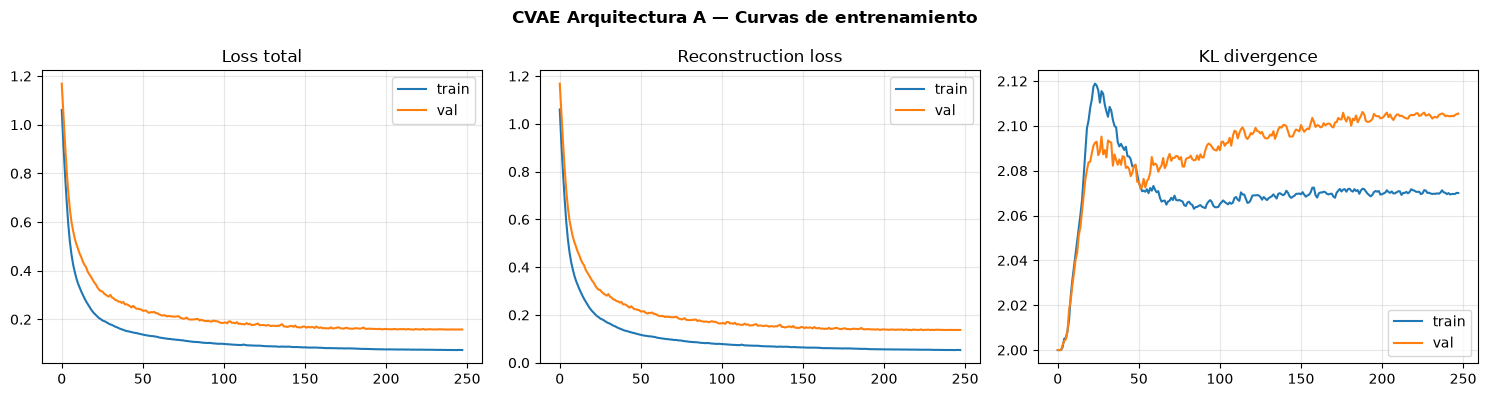

Mejor val loss: 0.1573


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history_a['train_loss'], label='train')
axes[0].plot(history_a['val_loss'],   label='val')
axes[0].set_title('Loss total')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_a['train_recon'], label='train')
axes[1].plot(history_a['val_recon'],   label='val')
axes[1].set_title('Reconstruction loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history_a['train_kl'], label='train')
axes[2].plot(history_a['val_kl'],   label='val')
axes[2].set_title('KL divergence')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('CVAE Arquitectura A — Curvas de entrenamiento', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_a_training.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mejor val loss: {history_a["best_val_loss"]:.4f}')

## 4. Evaluacion en validacion

In [7]:
metrics_val_a, scenarios_val_a = full_evaluation(
    model_a, X_val, C_val, x_scaler,
    n_scenarios=500, device=DEVICE, architecture='A'
)

print('Metricas en validacion:')
print(f'  MAE global:      {metrics_val_a["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_val_a["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_val_a["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_val_a["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_val_a["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_val_a["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_val_a["mmd"]:.4f}')

Generando 500 escenarios para 366 muestras...
Calculando metricas...
Metricas en validacion:
  MAE global:      57.3 MWh
  RMSE global:     158.7 MWh
  MAPE energia:    5.38%
  Coverage P5-P95: 75.9%
  Sharpness:       173.9 MWh
  Diversity ratio: 0.406
  MMD:             0.0055


In [8]:
metrics_val_a['per_province']

,provincia,mae_mwh,coverage,sharpness
0,buenos_aires,534.5,80.1,1755.000000
1,santa_fe,137.7,73.0,389.700012
2,cordoba,96.0,73.6,269.200012
3,chubut,95.9,59.9,202.100006
4,mendoza,44.2,74.2,130.899994
5,entre_rios,36.9,76.0,109.699997
6,chaco,35.8,81.4,118.199997
7,misiones,35.1,81.6,120.300003
8,tucuman,32.1,77.2,98.900002
9,corrientes,28.3,79.4,89.000000


## 5. Visualizacion de escenarios generados

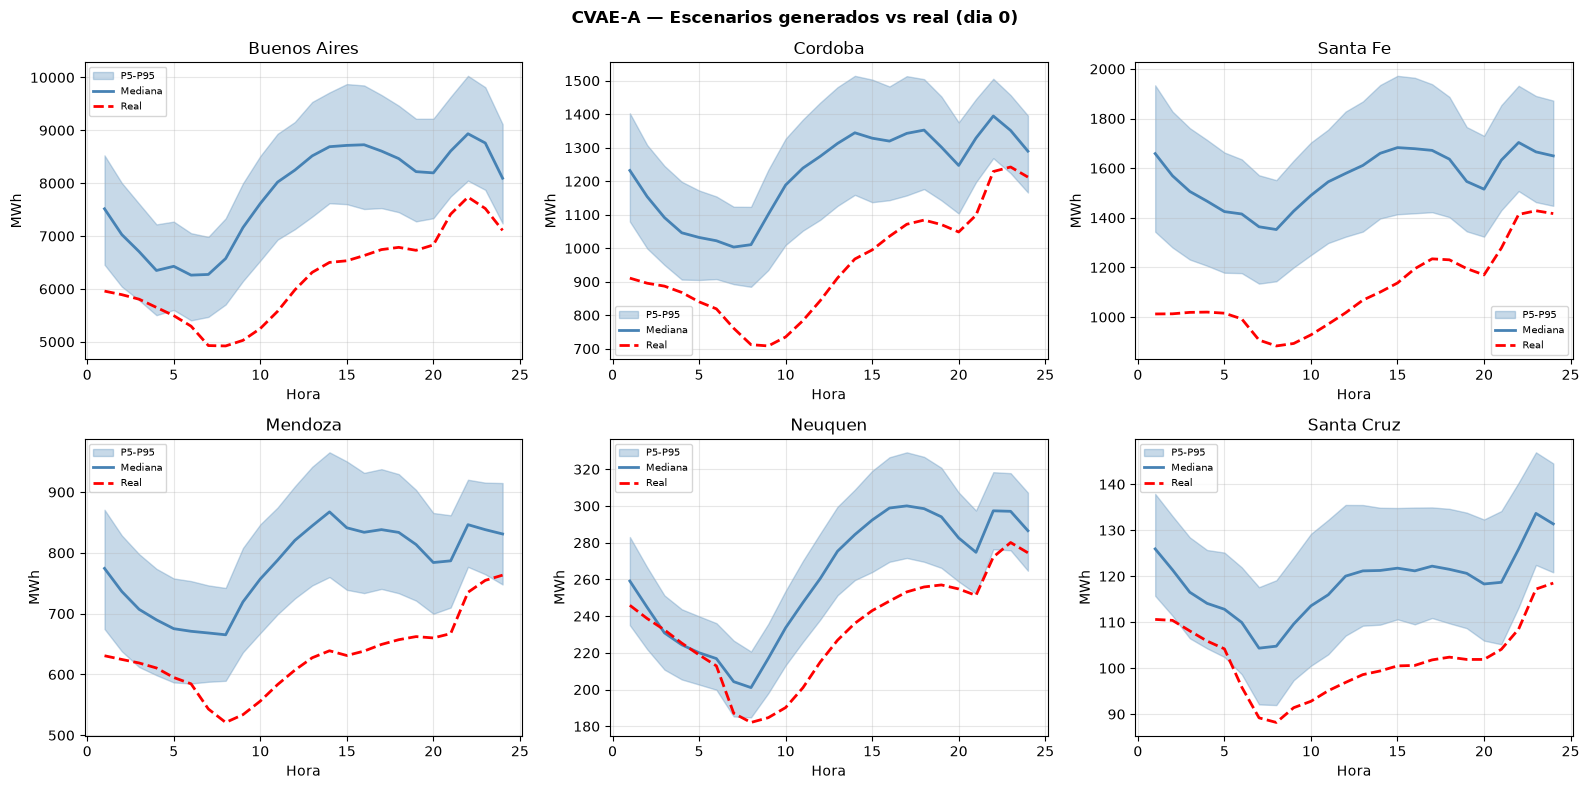

In [9]:
# Seleccionar un dia de val y visualizar los escenarios generados vs real
from evaluate_cvae import extract_province_a

day_idx = 0  # cambiar para ver otros dias

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
provinces_to_show = ['buenos_aires', 'cordoba', 'santa_fe', 'mendoza', 'neuquen', 'santa_cruz']

real_mwh = x_scaler.inverse_transform(X_val[day_idx:day_idx+1])
scen_mwh = np.stack([
    x_scaler.inverse_transform(scenarios_val_a[day_idx, s:s+1, :])
    for s in range(scenarios_val_a.shape[1])
], axis=0).squeeze()

for ax, prov in zip(axes.flat, provinces_to_show):
    real_prov = extract_province_a(real_mwh, prov).flatten()
    scen_prov = np.stack([extract_province_a(scen_mwh[s:s+1], prov).flatten() for s in range(len(scen_mwh))])
    p5  = np.percentile(scen_prov, 5,  axis=0)
    p50 = np.percentile(scen_prov, 50, axis=0)
    p95 = np.percentile(scen_prov, 95, axis=0)
    horas = range(1, 25)
    ax.fill_between(horas, p5, p95, alpha=0.3, color='steelblue', label='P5-P95')
    ax.plot(horas, p50,       color='steelblue', linewidth=2, label='Mediana')
    ax.plot(horas, real_prov, color='red',       linewidth=2, label='Real', linestyle='--')
    ax.set_title(prov.replace('_', ' ').title())
    ax.set_xlabel('Hora')
    ax.set_ylabel('MWh')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle(f'CVAE-A — Escenarios generados vs real (dia {day_idx})', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_a_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Resultado final en test

In [10]:
metrics_test_a, _ = full_evaluation(
    model_a, X_test, C_test, x_scaler,
    n_scenarios=500, device=DEVICE, architecture='A'
)

print('=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA A ===')
print(f'  MAE global:      {metrics_test_a["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_test_a["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_test_a["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_test_a["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_test_a["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_test_a["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_test_a["mmd"]:.4f}')

Generando 500 escenarios para 485 muestras...
Calculando metricas...
=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA A ===
  MAE global:      57.1 MWh
  RMSE global:     157.8 MWh
  MAPE energia:    5.23%
  Coverage P5-P95: 73.6%
  Sharpness:       176.5 MWh
  Diversity ratio: 0.397
  MMD:             0.0041


In [11]:
results_a = {
    'model': 'cvae_architecture_a',
    'val': {
        'mae_global':      float(round(metrics_val_a['mae_global'], 2)),
        'rmse_global':     float(round(metrics_val_a['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_val_a['mape_energy'], 4)),
        'coverage':        float(round(metrics_val_a['coverage'], 2)),
        'sharpness':       float(round(metrics_val_a['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_val_a['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_val_a['mmd'], 6)),
    },
    'test': {
        'mae_global':      float(round(metrics_test_a['mae_global'], 2)),
        'rmse_global':     float(round(metrics_test_a['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_test_a['mape_energy'], 4)),
        'coverage':        float(round(metrics_test_a['coverage'], 2)),
        'sharpness':       float(round(metrics_test_a['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_test_a['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_test_a['mmd'], 6)),
    },
}

with open(RESULTS_DIR / 'cvae_a_metrics.json', 'w') as f:
    json.dump(results_a, f, indent=2)
print('Metricas guardadas en results/cvae_a_metrics.json')

Metricas guardadas en results/cvae_a_metrics.json
